# Legacy soybean field illumination search

Historical quantity definitions and stored outputs. For the new organ-specific incident-total experiments, use `soybean_experiment_analysis.ipynb`, backed by `analyze_soybean_experiments.py`. Do not mix these historical totals with schema-2 results.

Aggregate repeated random 40-plant fields, compare broad and narrow leaves over row/column spacing, and rank parameter combinations for per-plant exposure and illumination intercepted per unit ground area.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
import pandas as pd

result_dir = next(path for path in [
    Path('out/field-illumination-search-inch-1-5x10-35'),
    Path('../out/field-illumination-search-inch-1-5x10-35'),
] if path.is_dir())
summary = pd.read_csv(result_dir / 'field_summary.csv')
plants = pd.read_csv(result_dir / 'plant_measurements.csv')
# Keep different measurement regions separate; set this when a search contains multiple ROI values.
analysis_roi = None
if 'roi' in summary:
    if analysis_roi is None and summary['roi'].nunique() > 1:
        raise ValueError('Set analysis_roi to analyze one measurement region at a time.')
    if analysis_roi is not None:
        summary = summary[np.isclose(summary['roi'], analysis_roi)].copy()
        plants = plants[plants['run_id'].isin(summary['run_id'])].copy()
print(f'{len(summary)} field runs; {len(plants)} plant measurements')
summary.head()

594 field runs; 23760 plant measurements


,run_id,asset_name,asset_folder,rows,columns,column_spacing_inches,row_spacing_inches,column_spacing,row_spacing,seed,...,total_area,total_flux_r,total_flux_g,total_flux_b,area_weighted_average_flux_r,area_weighted_average_flux_g,area_weighted_average_flux_b,mean_model_average_flux_r,mean_model_average_flux_g,mean_model_average_flux_b
0,0,broad,GeneratedAssets/Soybean/Broad,4,10,1.0,10.0,0.0254,0.2540,101,...,47.274811,1.237210,1.288292,1.269504,0.026171,0.027251,0.026854,0.026807,0.027899,0.027484
1,1,broad,GeneratedAssets/Soybean/Broad,4,10,1.0,10.0,0.0254,0.2540,202,...,47.924072,1.309028,1.366649,1.353222,0.027315,0.028517,0.028237,0.027001,0.028206,0.027928
2,2,broad,GeneratedAssets/Soybean/Broad,4,10,1.0,10.0,0.0254,0.2540,303,...,47.743576,1.281552,1.337088,1.320946,0.026842,0.028006,0.027668,0.026984,0.028170,0.027840
3,3,broad,GeneratedAssets/Soybean/Broad,4,10,1.0,12.5,0.0254,0.3175,101,...,47.274811,1.375693,1.433172,1.413492,0.029100,0.030316,0.029899,0.029693,0.030918,0.030483
4,4,broad,GeneratedAssets/Soybean/Broad,4,10,1.0,12.5,0.0254,0.3175,202,...,47.924080,1.458642,1.524131,1.510391,0.030437,0.031803,0.031516,0.030118,0.031492,0.031210


In [3]:
# Values are relative linear RGB, not calibrated PAR. Linear luminance is only a scalar ranking score.
luma = np.array([0.2126, 0.7152, 0.0722])
summary['mean_exposure'] = summary[[
    'area_weighted_average_flux_r', 'area_weighted_average_flux_g', 'area_weighted_average_flux_b'
]].to_numpy() @ luma
summary['total_intercepted'] = summary[['total_flux_r', 'total_flux_g', 'total_flux_b']].to_numpy() @ luma
# New ROI runs use measured cell area; older full-field CSVs retain the original denominator.
summary['allocated_ground_area'] = summary['measurement_ground_area'] if 'measurement_ground_area' in summary else (
    summary['rows'] * summary['row_spacing'] * summary['columns'] * summary['column_spacing']
)
summary['intercepted_per_ground_area'] = summary['total_intercepted'] / summary['allocated_ground_area']
plants['plant_exposure'] = plants[['average_flux_r', 'average_flux_g', 'average_flux_b']].to_numpy() @ luma
plants['plant_total_intercepted'] = plants[['total_flux_r', 'total_flux_g', 'total_flux_b']].to_numpy() @ luma
plant_stats = plants.groupby('run_id').agg(
    plant_exposure_mean=('plant_exposure', 'mean'),
    plant_exposure_std=('plant_exposure', 'std'),
    plant_exposure_min=('plant_exposure', 'min'),
    mean_total_intercepted_per_plant=('plant_total_intercepted', 'mean'),
    total_intercepted_per_plant_std=('plant_total_intercepted', 'std'),
    mean_leaf_area_per_plant=('total_area', 'mean'),
).reset_index()
summary = summary.merge(plant_stats, on='run_id', validate='one_to_one')
summary['plant_cv'] = summary['plant_exposure_std'] / summary['plant_exposure_mean']

In [4]:
# Seeds are repeated random 40-model subsets, not search parameters. Rank means across repeats.
keys = ['asset_name', 'row_spacing_inches', 'column_spacing_inches']
ranked = summary.groupby(keys).agg(
    repeats=('run_id', 'size'),
    mean_exposure=('mean_exposure', 'mean'),
    mean_exposure_std=('mean_exposure', 'std'),
    mean_total_intercepted_per_plant=('mean_total_intercepted_per_plant', 'mean'),
    mean_total_intercepted_per_plant_std=('mean_total_intercepted_per_plant', 'std'),
    mean_leaf_area_per_plant=('mean_leaf_area_per_plant', 'mean'),
    intercepted_per_ground_area=('intercepted_per_ground_area', 'mean'),
    intercepted_per_ground_area_std=('intercepted_per_ground_area', 'std'),
    plant_cv=('plant_cv', 'mean'),
    total_area=('total_area', 'mean'),
).reset_index()
best_mean_exposure = ranked.sort_values(['mean_exposure', 'plant_cv'], ascending=[False, True])
best_ground_interception = ranked.sort_values(
    ['intercepted_per_ground_area', 'plant_cv'], ascending=[False, True]
)
ranked.to_csv(result_dir / 'ranked_combinations.csv', index=False)
best_mean_exposure.head(15).to_csv(result_dir / 'best_mean_exposure.csv', index=False)
best_ground_interception.head(15).to_csv(result_dir / 'best_ground_interception.csv', index=False)
print('Best mean leaf-area irradiance')
display(best_mean_exposure.head(15))
print('Best intercepted illumination per allocated ground area')
display(best_ground_interception.head(15))

Best mean leaf-area irradiance


,asset_name,row_spacing_inches,column_spacing_inches,repeats,mean_exposure,mean_exposure_std,mean_total_intercepted_per_plant,mean_total_intercepted_per_plant_std,mean_leaf_area_per_plant,intercepted_per_ground_area,intercepted_per_ground_area_std,plant_cv,total_area
197,narrow,35.0,5.0,3,0.186492,0.001120,0.088395,0.001052,0.473982,0.782932,0.009321,0.217120,18.959276
188,narrow,32.5,5.0,3,0.184989,0.001181,0.087683,0.001048,0.473982,0.836362,0.009995,0.219345,18.959277
179,narrow,30.0,5.0,3,0.183310,0.001084,0.086887,0.001022,0.473982,0.897834,0.010565,0.221964,18.959277
170,narrow,27.5,5.0,3,0.180925,0.001234,0.085757,0.001069,0.473982,0.966713,0.012050,0.225151,18.959276
161,narrow,25.0,5.0,3,0.177679,0.001248,0.084218,0.001031,0.473982,1.044305,0.012782,0.230556,18.959277
196,narrow,35.0,4.5,3,0.177389,0.001149,0.084081,0.001119,0.473982,0.827469,0.011015,0.231090,18.959276
187,narrow,32.5,4.5,3,0.175937,0.001127,0.083393,0.001093,0.473982,0.883825,0.011584,0.233349,18.959276
178,narrow,30.0,4.5,3,0.174240,0.001116,0.082589,0.001091,0.473982,0.948244,0.012522,0.236096,18.959277
152,narrow,22.5,5.0,3,0.172628,0.001070,0.081824,0.000969,0.473982,1.127353,0.013352,0.238600,18.959275
169,narrow,27.5,4.5,3,0.172040,0.001196,0.081546,0.001098,0.473982,1.021384,0.013749,0.239657,18.959276


Best intercepted illumination per allocated ground area


,asset_name,row_spacing_inches,column_spacing_inches,repeats,mean_exposure,mean_exposure_std,mean_total_intercepted_per_plant,mean_total_intercepted_per_plant_std,mean_leaf_area_per_plant,intercepted_per_ground_area,intercepted_per_ground_area_std,plant_cv,total_area
0,broad,10.0,1.0,3,0.027656,0.000628,0.032947,0.000976,1.191187,5.106770,0.151330,0.585238,47.647486
99,narrow,10.0,1.0,3,0.065784,0.001498,0.031184,0.000943,0.473982,4.833521,0.146155,0.422082,18.959277
9,broad,12.5,1.0,3,0.030872,0.000758,0.036778,0.001159,1.191187,4.560500,0.143663,0.533353,47.647489
108,narrow,12.5,1.0,3,0.073633,0.001748,0.034905,0.001090,0.473982,4.328220,0.135161,0.374044,18.959274
18,broad,15.0,1.0,3,0.033958,0.000915,0.040455,0.001372,1.191187,4.180385,0.141748,0.479871,47.647491
117,narrow,15.0,1.0,3,0.081023,0.002081,0.038408,0.001274,0.473982,3.968880,0.131615,0.329854,18.959276
27,broad,17.5,1.0,3,0.036926,0.001122,0.043991,0.001640,1.191187,3.896397,0.145259,0.438230,47.647491
126,narrow,17.5,1.0,3,0.087949,0.002262,0.041692,0.001383,0.473982,3.692696,0.122532,0.292829,18.959275
1,broad,10.0,1.5,3,0.029865,0.000734,0.035579,0.001122,1.191187,3.676460,0.115960,0.615531,47.647489
36,broad,20.0,1.0,3,0.039769,0.001165,0.047379,0.001712,1.191187,3.671850,0.132661,0.408089,47.647489


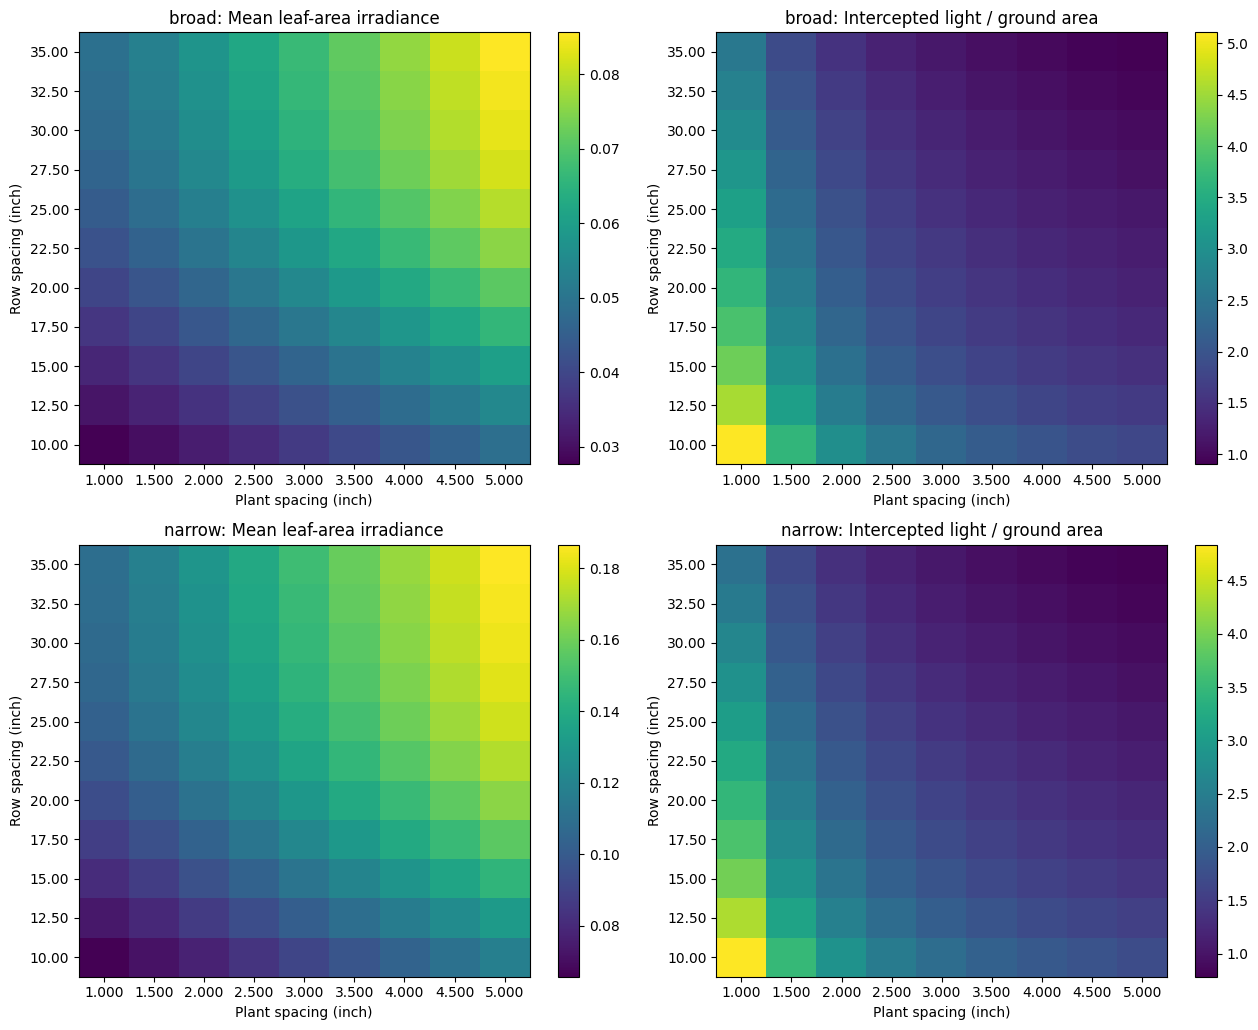

In [5]:
# Heatmaps show the mean over the three random model subsets.
fig, axes = plt.subplots(len(ranked['asset_name'].unique()), 2, figsize=(13, 5.2 * ranked['asset_name'].nunique()))
axes = np.atleast_2d(axes)
for row, (asset_name, group) in enumerate(ranked.groupby('asset_name')):
    for column, (metric, title) in enumerate([
        ('mean_exposure', 'Mean leaf-area irradiance'),
        ('intercepted_per_ground_area', 'Intercepted light / ground area'),
    ]):
        table = group.pivot(index='row_spacing_inches', columns='column_spacing_inches', values=metric).sort_index(ascending=False)
        image = axes[row, column].imshow(table, aspect='auto', cmap='viridis')
        axes[row, column].set(
            title=f'{asset_name}: {title}', xlabel='Plant spacing (inch)', ylabel='Row spacing (inch)'
        )
        axes[row, column].set_xticks(range(len(table.columns)), labels=[f'{v:.3f}' for v in table.columns])
        axes[row, column].set_yticks(range(len(table.index)), labels=[f'{v:.2f}' for v in table.index])
        fig.colorbar(image, ax=axes[row, column])
fig.tight_layout()
fig.savefig(result_dir / 'spacing_heatmaps.png', dpi=180, bbox_inches='tight')

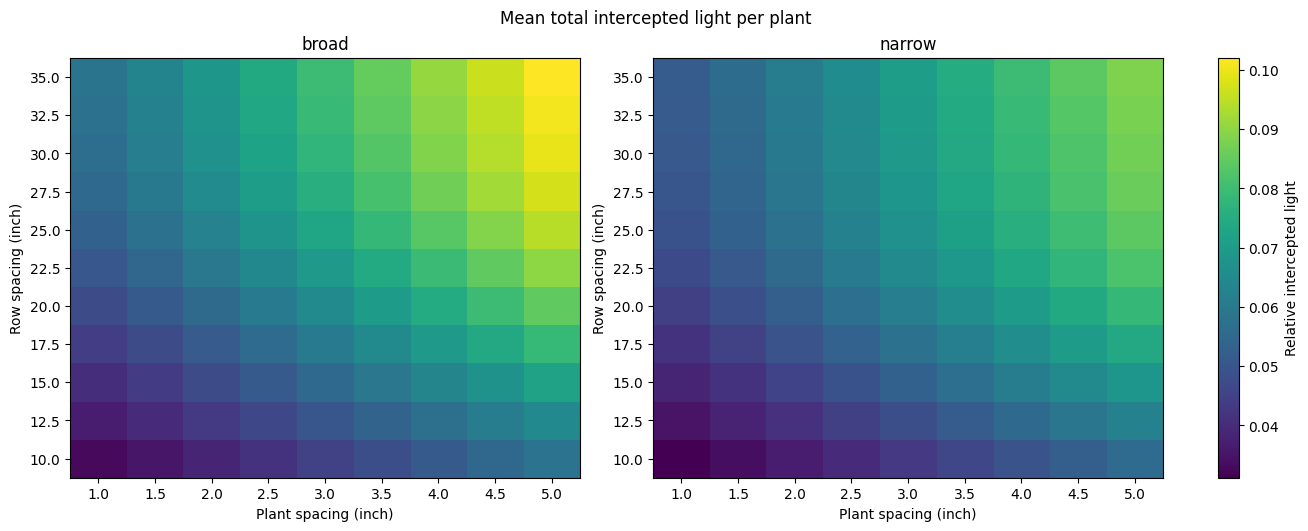

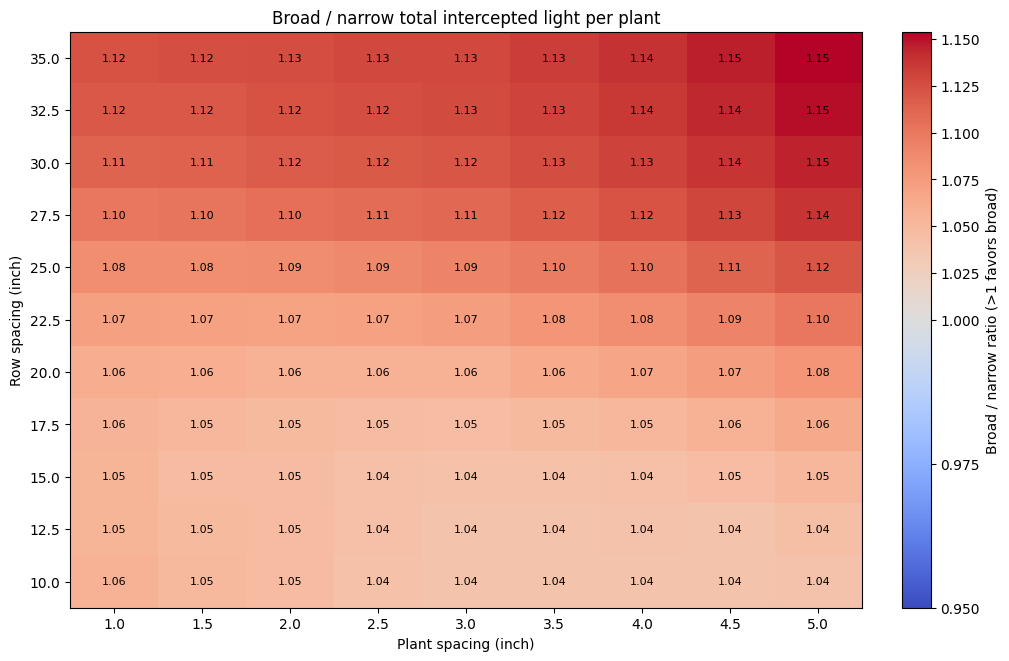

In [6]:
# Total intercepted light per plant includes leaf area; use one shared scale for direct comparison.
total_tables = {
    asset_name: group.pivot(
        index='row_spacing_inches', columns='column_spacing_inches',
        values='mean_total_intercepted_per_plant',
    ).sort_index(ascending=False)
    for asset_name, group in ranked.groupby('asset_name')
}
vmin = min(table.to_numpy().min() for table in total_tables.values())
vmax = max(table.to_numpy().max() for table in total_tables.values())
fig, axes = plt.subplots(1, len(total_tables), figsize=(13, 5.2), constrained_layout=True)
for ax, (asset_name, table) in zip(np.atleast_1d(axes), total_tables.items()):
    image = ax.imshow(table, aspect='auto', cmap='viridis', vmin=vmin, vmax=vmax)
    ax.set(
        title=asset_name, xlabel='Plant spacing (inch)', ylabel='Row spacing (inch)'
    )
    ax.set_xticks(range(len(table.columns)), labels=[f'{value:.1f}' for value in table.columns])
    ax.set_yticks(range(len(table.index)), labels=[f'{value:.1f}' for value in table.index])
fig.suptitle('Mean total intercepted light per plant')
fig.colorbar(image, ax=np.atleast_1d(axes), label='Relative intercepted light')
fig.savefig(result_dir / 'mean_total_intercepted_per_plant.png', dpi=180, bbox_inches='tight')

# A value above one means the broad-leaf plant intercepts more total light.
paired_total = ranked.pivot(
    index=['row_spacing_inches', 'column_spacing_inches'],
    columns='asset_name', values='mean_total_intercepted_per_plant',
)
ratio = (paired_total['broad'] / paired_total['narrow']).unstack().sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(10, 6.5), constrained_layout=True)
norm = TwoSlopeNorm(vmin=min(0.95, ratio.to_numpy().min()), vcenter=1.0, vmax=ratio.to_numpy().max())
image = ax.imshow(ratio, aspect='auto', cmap='coolwarm', norm=norm)
ax.set(
    title='Broad / narrow total intercepted light per plant',
    xlabel='Plant spacing (inch)', ylabel='Row spacing (inch)',
)
ax.set_xticks(range(len(ratio.columns)), labels=[f'{value:.1f}' for value in ratio.columns])
ax.set_yticks(range(len(ratio.index)), labels=[f'{value:.1f}' for value in ratio.index])
for row_index in range(ratio.shape[0]):
    for column_index in range(ratio.shape[1]):
        ax.text(column_index, row_index, f'{ratio.iloc[row_index, column_index]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=ax, label='Broad / narrow ratio (>1 favors broad)')
fig.savefig(result_dir / 'broad_narrow_total_interception_ratio.png', dpi=180, bbox_inches='tight')

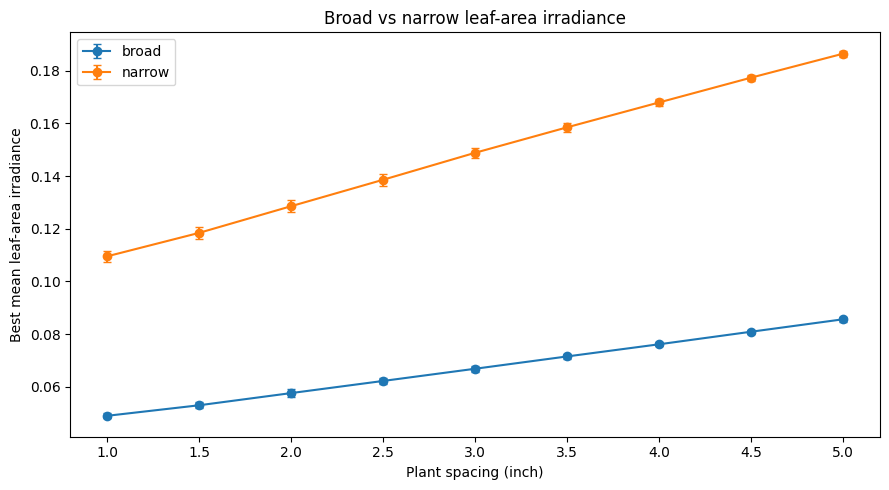

In [7]:
# Compare the best row distance at each column distance; error bars show random-library subset variation.
best_rows = (
    ranked.sort_values('mean_exposure', ascending=False)
    .groupby(['asset_name', 'column_spacing_inches'], as_index=False).first()
)
fig, ax = plt.subplots(figsize=(9, 5))
for asset_name, group in best_rows.groupby('asset_name'):
    ax.errorbar(
        group['column_spacing_inches'], group['mean_exposure'], yerr=group['mean_exposure_std'],
        marker='o', capsize=3, label=asset_name,
    )
ax.set(xlabel='Plant spacing (inch)', ylabel='Best mean leaf-area irradiance', title='Broad vs narrow leaf-area irradiance')
ax.legend()
fig.tight_layout()
fig.savefig(result_dir / 'broad_vs_narrow_optimum.png', dpi=180, bbox_inches='tight')

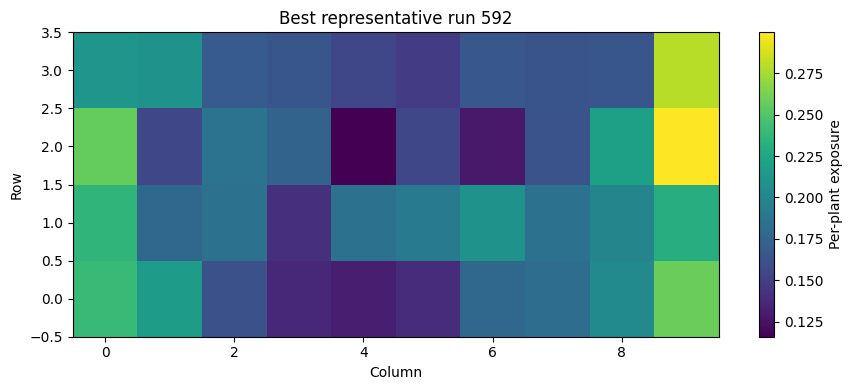

In [8]:
# Inspect spatial shading in a representative run from the best replicated combination.
winner = best_mean_exposure.iloc[0]
winner_runs = summary[
    (summary['asset_name'] == winner['asset_name'])
    & (summary['row_spacing_inches'] == winner['row_spacing_inches'])
    & (summary['column_spacing_inches'] == winner['column_spacing_inches'])
]
representative_index = (winner_runs['mean_exposure'] - winner['mean_exposure']).abs().idxmin()
selected_run_id = int(winner_runs.loc[representative_index, 'run_id'])
field = plants[plants['run_id'] == selected_run_id]
heatmap = field.pivot(index='row', columns='column', values='plant_exposure')
fig, ax = plt.subplots(figsize=(9, 4))
image = ax.imshow(heatmap, aspect='auto', origin='lower', cmap='viridis')
ax.set(title=f'Best representative run {selected_run_id}', xlabel='Column', ylabel='Row')
ax.set_xticks(range(len(heatmap.columns)), labels=heatmap.columns)
ax.set_yticks(range(len(heatmap.index)), labels=heatmap.index)
fig.colorbar(image, ax=ax, label='Per-plant exposure')
fig.tight_layout()
fig.savefig(result_dir / 'best_field_heatmap.png', dpi=180, bbox_inches='tight')